In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
from sklearn.cluster import KMeans
print("successfully installed")

successfully installed


In [3]:
import os
os.environ["OMP_NUM_THREADS"]="1"
from sklearn.cluster import KMeans

In [4]:
df=pd.read_csv(r"C:\Users\Dell\Customer Segmentation\\Mall_Customers.csv")
print(df)

     CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0             1    Male   19                  15                      39
1             2    Male   21                  15                      81
2             3  Female   20                  16                       6
3             4  Female   23                  16                      77
4             5  Female   31                  17                      40
..          ...     ...  ...                 ...                     ...
195         196  Female   35                 120                      79
196         197  Female   45                 126                      28
197         198    Male   32                 126                      74
198         199    Male   32                 137                      18
199         200    Male   30                 137                      83

[200 rows x 5 columns]


In [5]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [6]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB
None


In [7]:
print("number of rows:",df.shape[0])
print("number of columns:",df.shape[1])

number of rows: 200
number of columns: 5


In [8]:
print(df.isnull().sum())

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [9]:
print("Duplicate rows:",df.duplicated().sum())

Duplicate rows: 0


In [10]:
print(df.describe())

       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.000000               73.000000
max    200.000000   70.000000          137.000000               99.000000


In [11]:
print(df["Gender"].value_counts())

Gender
Female    112
Male       88
Name: count, dtype: int64


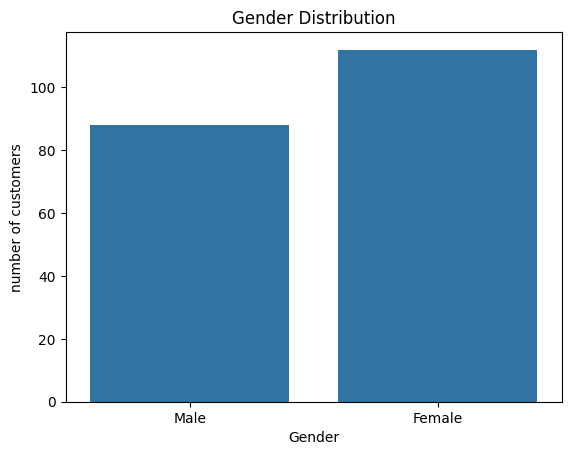

In [12]:
sns.countplot(x="Gender",data=df)
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("number of customers")
plt.show()

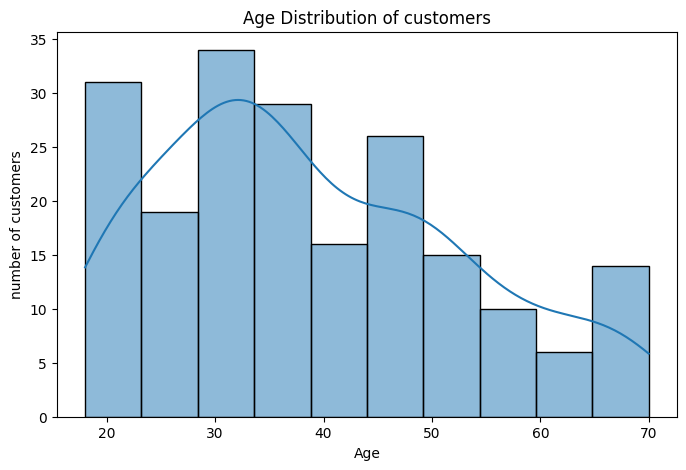

In [13]:
plt.figure(figsize=(8,5))
sns.histplot(df["Age"],bins=10,kde=True)
plt.title("Age Distribution of customers")
plt.xlabel("Age")
plt.ylabel("number of customers")
plt.show()

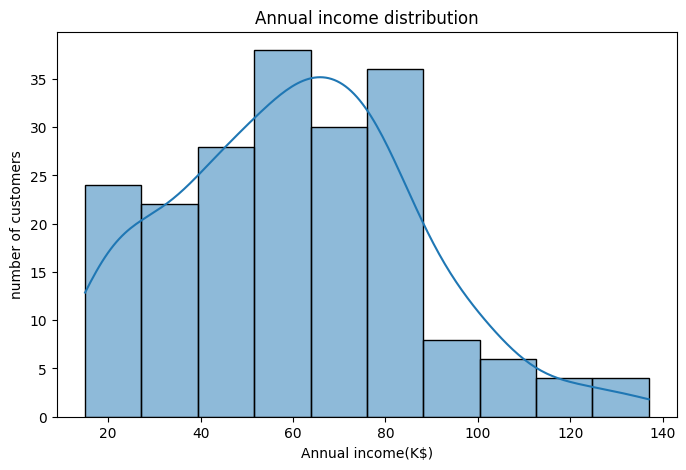

In [14]:
plt.figure(figsize=(8,5))
sns.histplot(df["Annual Income (k$)"],bins=10,kde=True)
plt.title("Annual income distribution")
plt.xlabel("Annual income(K$)")
plt.ylabel("number of customers")
plt.show()

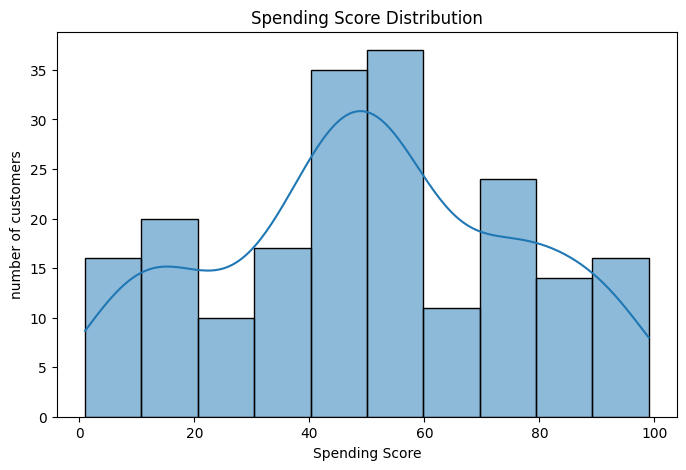

In [15]:
plt.figure(figsize=(8,5))
sns.histplot(df["Spending Score (1-100)"],bins=10,kde=True)
plt.title("Spending Score Distribution")
plt.xlabel("Spending Score")
plt.ylabel("number of customers")
plt.show()

In [16]:
x=df[["Annual Income (k$)","Spending Score (1-100)"]]

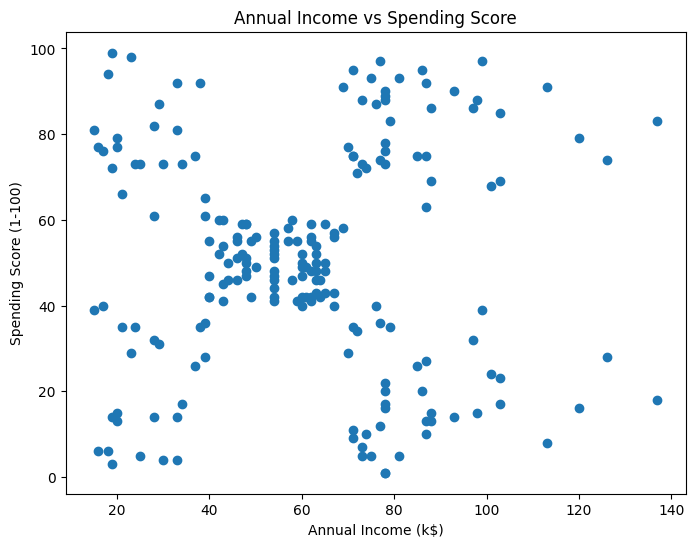

In [17]:
plt.figure(figsize=(8,6))
plt.scatter(x["Annual Income (k$)"],x["Spending Score (1-100)"])
plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()
            

In [18]:
inertia=[]
for k in range(1,11):
    kmeans=KMeans(n_clusters=k,random_state=42,n_init=10)
    kmeans.fit(x)
    inertia.append(kmeans.inertia_)

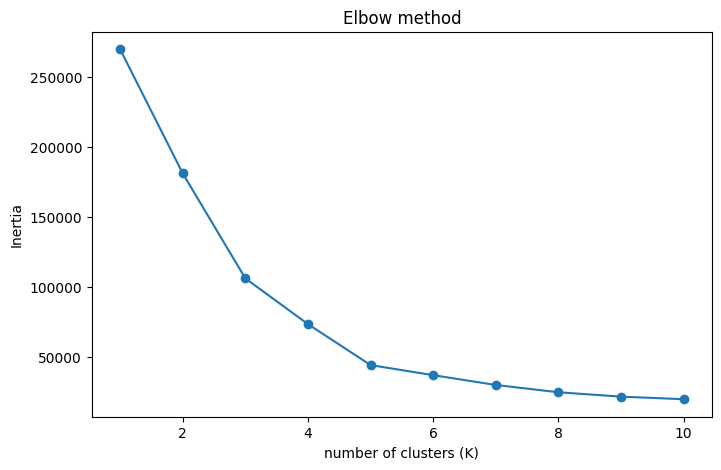

In [19]:
plt.figure(figsize=(8,5))
plt.plot(range(1,11),inertia,marker='o')
plt.title("Elbow method")
plt.xlabel("number of clusters (K)")
plt.ylabel("Inertia")
plt.show()

In [20]:
kmeans=KMeans(n_clusters=5,random_state=42,n_init=10)

In [21]:
kmeans.fit(x)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 2)","[[55.

In [22]:
df["Cluster"]=kmeans.labels_

In [23]:
print(kmeans.cluster_centers_)

[[55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [26.30434783 20.91304348]]


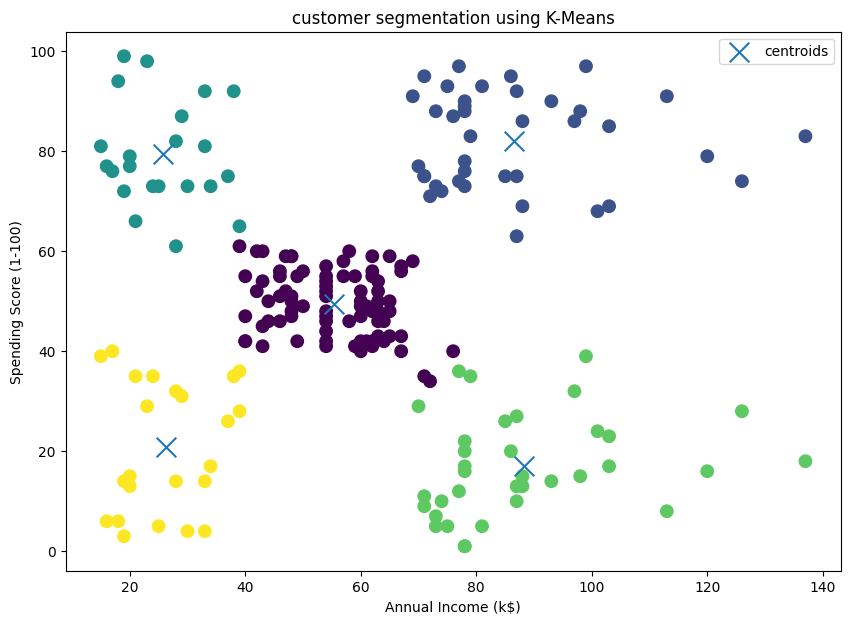

In [24]:
plt.figure(figsize=(10,7))
plt.scatter(x["Annual Income (k$)"],x["Spending Score (1-100)"],c=df["Cluster"],s=80)
plt.scatter(kmeans.cluster_centers_[:,0],kmeans.cluster_centers_[:,1],s=200,marker="x",label="centroids")
plt.title("customer segmentation using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.show()

In [25]:
cluster_summary=df.groupby("Cluster")[["Age","Annual Income (k$)","Spending Score (1-100)"]].mean()
print(cluster_summary)

               Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                       
0        42.716049           55.296296               49.518519
1        32.692308           86.538462               82.128205
2        25.272727           25.727273               79.363636
3        41.114286           88.200000               17.114286
4        45.217391           26.304348               20.913043


In [26]:
def segment_customer(row):
    income=row["Annual Income (k$)"]
    spending=row["Spending Score (1-100)"]
    if income >=70 and spending >=60:
        return "premium Customers"
    elif income >=70 and spending < 60:
        return "Careful Customers"
    elif income <40 and spending >=60:
        return "High Spending Low Income"
    elif income <40 and spending <60:
        return "Low value Customer"
    else:
        return "Average customers"


In [27]:
df["Customer Segment"]=df.apply(segment_customer,axis=1)

In [28]:
print(df[["CustomerID","Age","Annual Income (k$)","Spending Score (1-100)","Customer Segment"]])

     CustomerID  Age  Annual Income (k$)  Spending Score (1-100)  \
0             1   19                  15                      39   
1             2   21                  15                      81   
2             3   20                  16                       6   
3             4   23                  16                      77   
4             5   31                  17                      40   
..          ...  ...                 ...                     ...   
195         196   35                 120                      79   
196         197   45                 126                      28   
197         198   32                 126                      74   
198         199   32                 137                      18   
199         200   30                 137                      83   

             Customer Segment  
0          Low value Customer  
1    High Spending Low Income  
2          Low value Customer  
3    High Spending Low Income  
4          Low value Cu

In [29]:
print(df["Customer Segment"].value_counts())

Customer Segment
Average customers           78
Careful Customers           38
premium Customers           38
Low value Customer          23
High Spending Low Income    23
Name: count, dtype: int64


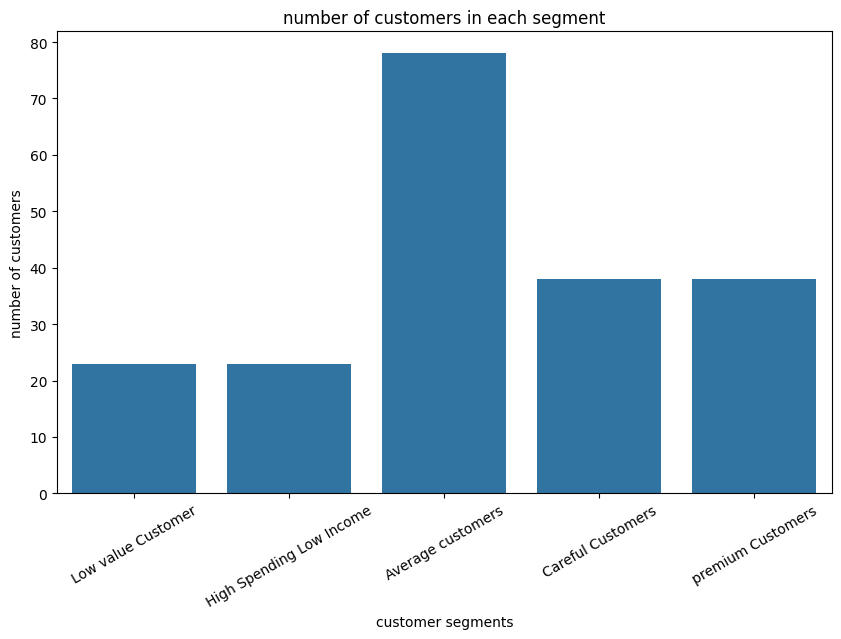

In [30]:
plt.figure(figsize=(10,6))
sns.countplot(x="Customer Segment",data=df)
plt.title("number of customers in each segment")
plt.xlabel("customer segments")
plt.ylabel("number of customers")
plt.xticks(rotation=30)
plt.show()

In [31]:
df.to_csv("customer_segmentation_result.csv",index=False)
print("customer segmentation results saved successfully")

customer segmentation results saved successfully
